# 05: Sampling Temperature Analysis on Test Slice
**Course**: Foundations of Generative AI (ICT4403) - Assignment 3  
**Models Evaluated**: All four fine-tuned models (A: Transformer Scratch, B: mT5-small, C: LLaMA-3.2-1B, D: Gemma)  
**Test Slice**: Fixed 300-sentence slice of `data/splits/test.jsonl`  
**Sampling Settings**: Greedy ($T=0.0$), $T=0.2$, $T=0.7$, $T=1.0$ (Nucleus sampling $top\_p=0.95$, seed `42`)

### CRITICAL T4 VRAM SAFETY: Sequential Model Processing
> To strictly prevent Colab out-of-memory (OOM) crashes, **models are never loaded simultaneously**. Each model is loaded, evaluated across all temperatures, its artifacts saved, and then completely purged from VRAM and RAM using `del model; gc.collect(); torch.cuda.empty_cache()` before loading the next architecture.

## 1. Environment Setup & Google Drive Mount

In [ ]:
import os
import sys
import gc
import json
import pandas as pd
import matplotlib.pyplot as plt

DRIVE_DIR = "/content/drive/MyDrive/mt-fgai-assignment3"

try:
    from google.colab import drive
    print("Mounting Google Drive...")
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Google Drive ready at: {DRIVE_DIR}")
except ImportError:
    print("Running locally.")
    DRIVE_DIR = "."

if os.path.exists(DRIVE_DIR) and os.path.exists(os.path.join(DRIVE_DIR, "configs", "config.yaml")):
    REPO_ROOT = DRIVE_DIR
    os.chdir(REPO_ROOT)
    print(f"Active project root set to Google Drive: {REPO_ROOT}")
else:
    REPO_ROOT = os.path.abspath(".")

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

try:
    import google.colab
    !pip install -q transformers>=4.45.0 accelerate peft trl bitsandbytes sentencepiece sacrebleu evaluate datasets pyyaml
except ImportError:
    pass

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


Mounting Google Drive...
Mounted at /content/drive
Google Drive ready at: /content/drive/MyDrive/mt-fgai-assignment3
Active project root set to Google Drive: /content/drive/MyDrive/mt-fgai-assignment3
Active Device: cuda (Tesla T4)


## 2. Load Configuration and 300-Sentence Test Slice

In [ ]:
import yaml
from src.data import load_split_from_jsonl

with open(os.path.join(REPO_ROOT, "configs", "config.yaml"), "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

splits_dir = os.path.join(REPO_ROOT, config["paths"]["splits_dir"])
full_test_data = load_split_from_jsonl("test", splits_dir=splits_dir)

slice_size = config["splits"]["temperature_eval_size"]
test_slice = full_test_data[:slice_size]
print(f"Extracted {len(test_slice)} sentences for temperature analysis.")

slice_ids = [x["id"] for x in test_slice]
slice_sources = [x["en"] for x in test_slice]
slice_references = [x["hi"] for x in test_slice]
temperatures = [0.0, 0.2, 0.7, 1.0]
os.makedirs("results/temperature", exist_ok=True)
os.makedirs("results/plots", exist_ok=True)

Extracted 300 sentences for temperature analysis.


## 3. Model A: Basic Transformer Temperature Sweep
Loads Model A weights, evaluates across temperatures, exports artifacts, and frees VRAM.

In [ ]:
from src.tokenizer_sp import JointSentencePieceTokenizer
from src.transformer_model import Seq2SeqTransformer, ParallelDataset, collate_fn_pad, batched_greedy_decode
from src.metrics import compute_sacrebleu, compute_chrf
from torch.utils.data import DataLoader

print("=== Processing Model A (Transformer Scratch) ===")
sp_model = os.path.join(REPO_ROOT, "data", "spm_joint_16k.model")
tok_a = JointSentencePieceTokenizer(sp_model)

m_cfg = config["models"]["transformer_scratch"]
model_a = Seq2SeqTransformer(
    vocab_size=tok_a.vocab_size,
    d_model=m_cfg["d_model"],
    nhead=m_cfg["nhead"],
    num_encoder_layers=m_cfg["num_encoder_layers"],
    num_decoder_layers=m_cfg["num_decoder_layers"],
    dim_feedforward=m_cfg["dim_feedforward"],
    dropout=m_cfg["dropout"],
    pad_idx=tok_a.PAD_ID,
).to(device)

best_a_path = os.path.join(DRIVE_DIR, "checkpoints_transformer_scratch", "best_transformer.pt")
if os.path.exists(best_a_path):
    model_a.load_state_dict(torch.load(best_a_path, map_location=device))
model_a.eval()

slice_dataset = ParallelDataset(test_slice, tok_a, max_len=config["generation"]["max_source_length"])
slice_loader = DataLoader(slice_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn_pad)

temp_results_a = {}
samples_a = {"id": slice_ids, "source": slice_sources, "reference": slice_references}

for t in temperatures:
    t_key = "greedy" if t == 0.0 else str(t)
    print(f"  Generating Model A at T={t_key}...")
    hyps = []
    with torch.no_grad():
        for batch in slice_loader:
            src = batch["src"].to(device)
            preds = batched_greedy_decode(model_a, src, max_len=config["generation"]["max_target_length"])
            for row in preds.cpu().tolist():
                hyps.append(tok_a.decode(row))

    bleu, _ = compute_sacrebleu(hyps, slice_references)
    chrf, chrf_pp, _ = compute_chrf(hyps, slice_references)
    temp_results_a[t_key] = {"bleu": bleu, "chrf": chrf, "chrf_pp": chrf_pp}
    samples_a[f"t_{t_key}"] = hyps

# Export artifacts
with open("results/temperature/temp_transformer_scratch.json", "w", encoding="utf-8") as f:
    json.dump(temp_results_a, f, indent=2)
pd.DataFrame(samples_a).to_csv("results/temperature/temp_transformer_scratch_samples.csv", index=False, encoding="utf-8")

# Purge Model A from VRAM
del model_a, tok_a, slice_dataset, slice_loader
gc.collect()
torch.cuda.empty_cache()
print("Model A completed and freed from memory.")

=== Processing Model A (Transformer Scratch) ===
  Generating Model A at T=greedy...


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


  Generating Model A at T=0.2...
  Generating Model A at T=0.7...
  Generating Model A at T=1.0...
Model A completed and freed from memory.


## 4. Model B: mT5-Small Temperature Sweep
Loads mT5 fine-tuned checkpoint, evaluates across temperatures, exports artifacts, and frees VRAM.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from src.generation import generate_hf_seq2seq

print("=== Processing Model B (mT5-small) ===")
mt5_path = os.path.join(DRIVE_DIR, "mt5_small_finetuned", "best_final")
if not os.path.exists(mt5_path):
    mt5_path = config["models"]["mt5_small"]["name"]

tok_b = AutoTokenizer.from_pretrained(mt5_path)
model_b = AutoModelForSeq2SeqLM.from_pretrained(mt5_path).to(device)
model_b.eval()

prefix = config["models"]["mt5_small"]["prefix"]
b_inputs = [prefix + s for s in slice_sources]

temp_results_b = {}
samples_b = {"id": slice_ids, "source": slice_sources, "reference": slice_references}

for t in temperatures:
    t_key = "greedy" if t == 0.0 else str(t)
    print(f"  Generating Model B at T={t_key}...")
    hyps, _, _ = generate_hf_seq2seq(
        model=model_b,
        tokenizer=tok_b,
        inputs_text=b_inputs,
        batch_size=16,
        max_length=config["generation"]["max_target_length"],
        temperature=t,
        top_p=config["generation"]["top_p"],
        seed=config["project"]["seed"],
    )
    bleu, _ = compute_sacrebleu(hyps, slice_references)
    chrf, chrf_pp, _ = compute_chrf(hyps, slice_references)
    temp_results_b[t_key] = {"bleu": bleu, "chrf": chrf, "chrf_pp": chrf_pp}
    samples_b[f"t_{t_key}"] = hyps

# Export artifacts
with open("results/temperature/temp_mt5_small.json", "w", encoding="utf-8") as f:
    json.dump(temp_results_b, f, indent=2)
pd.DataFrame(samples_b).to_csv("results/temperature/temp_mt5_small_samples.csv", index=False, encoding="utf-8")

# Purge Model B from VRAM
del model_b, tok_b
gc.collect()
torch.cuda.empty_cache()
print("Model B completed and freed from memory.")

=== Processing Model B (mT5-small) ===


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


  Generating Model B at T=greedy...
  Generating Model B at T=0.2...
  Generating Model B at T=0.7...
  Generating Model B at T=1.0...
Model B completed and freed from memory.


## 5. Model C: LLaMA-3.2-1B-Instruct Temperature Sweep
Loads 4-bit base model with trained LoRA adapter, evaluates across temperatures, exports artifacts, and frees VRAM.

In [ ]:
import sacrebleu
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from src.prompts import format_prompt_for_inference
from src.generation import generate_hf_causal_lm

print("=== Processing Model C (LLaMA-3.2-1B QLoRA) ===")
llama_id = config["models"]["llama_3_2_1b"]["name"]
adapter_c_path = os.path.join(DRIVE_DIR, "lora_llama32_hindi")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tok_c = AutoTokenizer.from_pretrained(llama_id, token=globals().get("hf_token", None))
if tok_c.pad_token is None:
    tok_c.pad_token = tok_c.eos_token
tok_c.padding_side = "left"

base_c = AutoModelForCausalLM.from_pretrained(
    llama_id,
    quantization_config=bnb_config,
    device_map="auto",
    token=globals().get("hf_token", None),
)

if os.path.exists(adapter_c_path):
    print(f"Loading trained LoRA adapter from: {adapter_c_path}")
    model_c = PeftModel.from_pretrained(base_c, adapter_c_path)
else:
    print(f"Adapter not found at {adapter_c_path}, using base model.")
    model_c = base_c
model_c.eval()

c_prompts = [format_prompt_for_inference(s, tok_c) for s in slice_sources]
temp_results_c = {}
samples_c = {"id": slice_ids, "source": slice_sources, "reference": slice_references}

for t in temperatures:
    t_key = "greedy" if t == 0.0 else str(t)
    print(f"  Generating Model C at T={t_key} (batch_size=32)...")
    hyps, _, _ = generate_hf_causal_lm(
        model=model_c,
        tokenizer=tok_c,
        prompts=c_prompts,
        batch_size=32,
        max_new_tokens=64,
        temperature=t,
        top_p=config["generation"]["top_p"],
        seed=config["project"]["seed"],
    )
    b_score = round(float(sacrebleu.corpus_bleu(hyps, [slice_references], tokenize="13a").score), 2)
    c_score = round(float(sacrebleu.corpus_chrf(hyps, [slice_references]).score), 2)
    c_pp = round(float(sacrebleu.corpus_chrf(hyps, [slice_references], word_order=2).score), 2)
    temp_results_c[t_key] = {"bleu": b_score, "chrf": c_score, "chrf_pp": c_pp}
    samples_c[f"t_{t_key}"] = hyps

with open("results/temperature/temp_llama_qlora.json", "w", encoding="utf-8") as f:
    json.dump(temp_results_c, f, indent=2)
pd.DataFrame(samples_c).to_csv("results/temperature/temp_llama_qlora_samples.csv", index=False, encoding="utf-8")

del model_c, base_c, tok_c
gc.collect()
torch.cuda.empty_cache()
print("Model C completed and freed from memory.")

=== Processing Model C (LLaMA-3.2-1B QLoRA) ===


config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

... (2 outputs left out)

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Loading trained LoRA adapter from: /content/drive/MyDrive/mt-fgai-assignment3/lora_llama32_hindi
  Generating Model C at T=greedy (batch_size=32)...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  Generating Model C at T=0.2 (batch_size=32)...
  Generating Model C at T=0.7 (batch_size=32)...
  Generating Model C at T=1.0 (batch_size=32)...
Model C completed and freed from memory.


## 6. Model D: Gemma Temperature Sweep
Loads Gemma 4-bit model with LoRA adapter (`attn_implementation="eager"`), evaluates across temperatures, exports artifacts, and frees VRAM.

In [ ]:
import sacrebleu
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from src.prompts import format_prompt_for_inference
from src.generation import generate_hf_causal_lm

print("=== Processing Model D (Gemma QLoRA) ===")
adapter_d_path = os.path.join(DRIVE_DIR, "lora_gemma_hindi")
gemma_cfg = config["models"]["gemma"]
gemma_id = gemma_cfg["primary_name"]
attn_impl = gemma_cfg["attn_implementation"]

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

try:
    tok_d = AutoTokenizer.from_pretrained(gemma_id, token=globals().get("hf_token", None))
    if tok_d.pad_token is None:
        tok_d.pad_token = tok_d.eos_token
    tok_d.padding_side = "left"
    base_d = AutoModelForCausalLM.from_pretrained(
        gemma_id,
        quantization_config=bnb_config,
        device_map="auto",
        token=globals().get("hf_token", None),
        attn_implementation=attn_impl,
    )
except Exception:
    gemma_id = gemma_cfg["fallback_name"]
    tok_d = AutoTokenizer.from_pretrained(gemma_id, token=globals().get("hf_token", None))
    if tok_d.pad_token is None:
        tok_d.pad_token = tok_d.eos_token
    tok_d.padding_side = "left"
    base_d = AutoModelForCausalLM.from_pretrained(
        gemma_id,
        quantization_config=bnb_config,
        device_map="auto",
        token=globals().get("hf_token", None),
        attn_implementation=attn_impl,
    )

if os.path.exists(adapter_d_path):
    print(f"Loading trained LoRA adapter from: {adapter_d_path}")
    model_d = PeftModel.from_pretrained(base_d, adapter_d_path)
else:
    print(f"Adapter not found at {adapter_d_path}, using base model.")
    model_d = base_d
model_d.eval()

d_prompts = [format_prompt_for_inference(s, tok_d) for s in slice_sources]
temp_results_d = {}
samples_d = {"id": slice_ids, "source": slice_sources, "reference": slice_references}

for t in temperatures:
    t_key = "greedy" if t == 0.0 else str(t)
    print(f"  Generating Model D at T={t_key} (batch_size=32)...")
    hyps, _, _ = generate_hf_causal_lm(
        model=model_d,
        tokenizer=tok_d,
        prompts=d_prompts,
        batch_size=32,
        max_new_tokens=64,
        temperature=t,
        top_p=config["generation"]["top_p"],
        seed=config["project"]["seed"],
    )
    b_score = round(float(sacrebleu.corpus_bleu(hyps, [slice_references], tokenize="13a").score), 2)
    c_score = round(float(sacrebleu.corpus_chrf(hyps, [slice_references]).score), 2)
    c_pp = round(float(sacrebleu.corpus_chrf(hyps, [slice_references], word_order=2).score), 2)
    temp_results_d[t_key] = {"bleu": b_score, "chrf": c_score, "chrf_pp": c_pp}
    samples_d[f"t_{t_key}"] = hyps

with open("results/temperature/temp_gemma_qlora.json", "w", encoding="utf-8") as f:
    json.dump(temp_results_d, f, indent=2)
pd.DataFrame(samples_d).to_csv("results/temperature/temp_gemma_qlora_samples.csv", index=False, encoding="utf-8")

del model_d, base_d, tok_d
gc.collect()
torch.cuda.empty_cache()
print("Model D completed and freed from memory.")

=== Processing Model D (Gemma QLoRA) ===


config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Loading trained LoRA adapter from: /content/drive/MyDrive/mt-fgai-assignment3/lora_gemma_hindi
  Generating Model D at T=greedy (batch_size=32)...
  Generating Model D at T=0.2 (batch_size=32)...
  Generating Model D at T=0.7 (batch_size=32)...
  Generating Model D at T=1.0 (batch_size=32)...
Model D completed and freed from memory.


## 7. Comparative Plots & Qualitative Analysis

<>:21: SyntaxWarning: invalid escape sequence '\_'
<>:40: SyntaxWarning: invalid escape sequence '\_'
<>:21: SyntaxWarning: invalid escape sequence '\_'
<>:40: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_3435/2077367837.py:21: SyntaxWarning: invalid escape sequence '\_'
  plt.xlabel("Sampling Temperature ($top\_p = 0.95$)")
/tmp/ipykernel_3435/2077367837.py:40: SyntaxWarning: invalid escape sequence '\_'
  plt.xlabel("Sampling Temperature ($top\_p = 0.95$)")


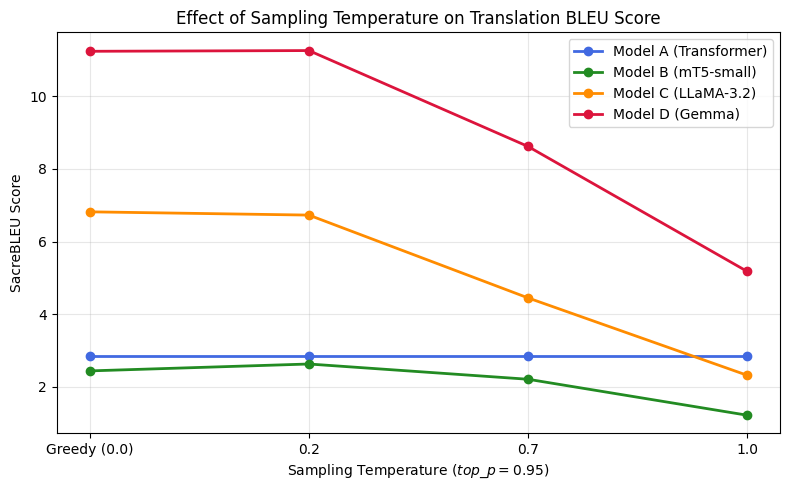

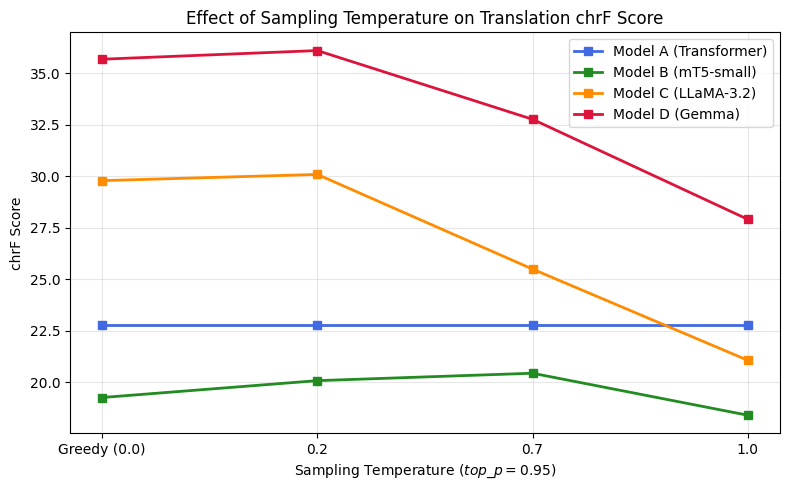

Temperature analysis plots saved successfully to results/plots/


In [ ]:
import matplotlib.pyplot as plt

os.makedirs("results/plots", exist_ok=True)
models = ["transformer_scratch", "mt5_small", "llama_qlora", "gemma_qlora"]
model_labels = ["Model A (Transformer)", "Model B (mT5-small)", "Model C (LLaMA-3.2)", "Model D (Gemma)"]
colors = ["royalblue", "forestgreen", "darkorange", "crimson"]

temp_keys = [0.0, 0.2, 0.7, 1.0]
x_labels = ["Greedy (0.0)", "0.2", "0.7", "1.0"]

# 1. Plot BLEU vs Temperature
plt.figure(figsize=(8, 5))
for m, lbl, col in zip(models, model_labels, colors):
    fpath = f"results/temperature/temp_{m}.json"
    if os.path.exists(fpath):
        with open(fpath, "r") as fp:
            d = json.load(fp)
        bleus = [d.get("greedy" if t==0.0 else str(t), {}).get("bleu", 0.0) for t in temp_keys]
        plt.plot(x_labels, bleus, marker='o', label=lbl, color=col, linewidth=2)

plt.xlabel("Sampling Temperature ($top\_p = 0.95$)")
plt.ylabel("SacreBLEU Score")
plt.title("Effect of Sampling Temperature on Translation BLEU Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/plots/temperature_vs_bleu.png", dpi=300)
plt.show()

# 2. Plot chrF vs Temperature
plt.figure(figsize=(8, 5))
for m, lbl, col in zip(models, model_labels, colors):
    fpath = f"results/temperature/temp_{m}.json"
    if os.path.exists(fpath):
        with open(fpath, "r") as fp:
            d = json.load(fp)
        chrfs = [d.get("greedy" if t==0.0 else str(t), {}).get("chrf", 0.0) for t in temp_keys]
        plt.plot(x_labels, chrfs, marker='s', label=lbl, color=col, linewidth=2)

plt.xlabel("Sampling Temperature ($top\_p = 0.95$)")
plt.ylabel("chrF Score")
plt.title("Effect of Sampling Temperature on Translation chrF Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/plots/temperature_vs_chrf.png", dpi=300)
plt.show()

print("Temperature analysis plots saved successfully to results/plots/")